In [1]:
from pathlib import Path
import sys, time
def _find_root():
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "C" / "evoca.h").is_file():
            return c
    raise FileNotFoundError("no C/evoca.h above cwd")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "python"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evoca_py import (EvoCA, import_run, make_gol_lut, make_random_lut,
                      pack_lut, lut_bit_index, LUT_BITS, LUT_BYTES)
WS = "Ring-complexity"
_T0 = time.time()
print("repo root:", ROOT)

repo root: /Users/n/Projects/EvoCA


# Ring-complexity: how far does the evolved rule reach, what does it cost, and is the ring class stable?

**Question.** The LUT is indexed by `(v_x, n1, n2, n3)`: counts of active cells in ring 1 (distance 1),
ring 2 (distance sqrt 2) and ring 3 (distance 2). The *ring level* of a LUT is the minimum ring set it
actually conditions on: **level 1** = `(v_x, n1)` only, **level 2** = also n2 (Game of Life is level 2),
**level 3** = depends on n3 (`lut_complexity` classifier in `C/evoca.c`, read via `sim.get_lut_complexity()`).
This workstream asks (i) how the spatial reach of the evolved rule changes over evolution, (ii) what reach
costs (`tax_ring * level` per alive cell per step), and (iii) whether a ring class is *stable* against
competition (Track 1, `mu_lut = 0`) and against mutation (Track 2, ring-bounded mutation, not built).

**Links.** This workstream has no finished digests or scans yet (`digests/` and `Scans/` are empty), so
there is nothing to link there; the sources are
[`Docs/EvoCA_research_stability.md`](../../Docs/EvoCA_research_stability.md) (two-track plan),
[`Docs/EvoCA_research_directions.md`](../../Docs/EvoCA_research_directions.md) section 8 (tax design),
[`Docs/devlog/2026-05-16_parallel-batch.md`](../../Docs/devlog/2026-05-16_parallel-batch.md) (S2b), and
[`tests/test_ring_tax.py`](../../tests/test_ring_tax.py). Recipes made here live in `Runs/`.

**Reading guide.** The "example runs" below are small illustrations (N <= 96, <= 3000 steps, one or a few
seeds). They show phenomenology; they are **not** campaign results.

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel. Runs now use the capped mouthful (`food_cap=1`, the A9 fix); the outputs stored in this notebook were computed before it.

## Open issues snapshot

The cell below renders `ISSUES.md` as of the last execution of this notebook. `ISSUES.md` is the source of
truth; edit it there, not here.

In [2]:
display(Markdown((ROOT / "Research" / WS / "ISSUES.md").read_text()))

# Ring-complexity: issues and directions
_Updated 2026-10-15_

## Decisions needed (N)
- **RING-D1**: Commission the Track-1 ring-class dominance campaign now? — Options: (a) yes, as an analysis-only campaign on main (no C change; Python-side level-k LUT constructors, LUT hash as the A/B tag at `mu_lut=0`); (b) first build the harness pieces (RING-N2) and the viability screen as a short pilot, then commission. Recommendation: (b) then (a). The notebook pilot (`Ring-complexity.ipynb`, 2026-05-19 section) shows the plan is runnable with no C change; the null spread is modest (F sd about 0.09) but untaxed class effects are of similar size, so the design needs many LUT draws per class. Blocks RING-N1. Source: `Docs/EvoCA_research_stability.md` sections C.5, C.10, F.
- **RING-D2**: Tax schedule for the ring ladder — keep `tax_ring * level` (linear, current, exactly tested in `tests/test_ring_tax.py`), or add a nonlinear / effective-dependence variant? — Linear makes the cost differential between classes a built-in selection pressure, so a "level 1 wins under tax" result is partly by construction. Recommendation: keep linear for the first A/B, and use `eff_activity`-based used-entry counts (merged F1) as the sharper alternative later (research directions section 8). Blocks nothing immediately; shapes RING-N3.
- **RING-D3**: Which "climb" metric defines success for the ring-ladder A/B (#5)? — Options: population fraction at level 3 at the end; time to level-3 majority; level-weighted mean; or net fraction relative to a neutral-mutation baseline (RING-N4). No spec exists (board lists #5 as queued with no headline). Recommendation: report the fraction relative to the neutral baseline. Blocks RING-N3.

## Open questions
- **RING-Q1**: How much of "ring level climbs under mutation" is mutational entropy rather than selection? — In the example runs (notebook, ring-ladder section; N=96, one seed, not a campaign result) a GoL or level-1 start with `mu_lut=0.002` and no tax goes to >90% level 3 within ~500 steps. Hypothesis (untested): level-1/2 LUTs are a tiny tied subset of LUT space and one bit flip breaks the tie. Needs a neutral-mutation control (RING-N4) before any "evolution climbs" claim.
- **RING-Q2**: Is a ring class stable against competition at `mu_lut=0`, controlling for LUT identity? — Pilot (notebook, 2026-05-19 section; N=64, 3 seeds, 8 LUTs per class): untaxed classes coexist with a weak seed-dependent level-1 gain; null control (6 seeds, two random level-3 pools) gives final F sd about 0.09. Class effects of that size are not distinguishable from LUT-draw noise with so few draws; needs many draws per class (`EvoCA_research_stability.md` C.6, G).
- **RING-Q3**: What is the genelife-like "no resource flow" arm in EvoCA? — `food_inc=0` is not frozen: the initial food stock lets the population fill the lattice, then turnover largely stops (example run: 67% level 3 at t=2000 vs 100% at `food_inc=0.01`; one seed, confounded with number of births). With any substantial `tax_ring` and `food_inc<=0.003` the population goes extinct. Need an explicit design of the null arm (matched birth count, or a low-but-viable food_inc) before the #5 A/B (research directions section 8) is interpretable.
- **RING-Q4**: Does the selection survive in a regime where the lattice is not saturated? — In all example runs the lattice fills (alive = N*N) within a few hundred steps, so selection acts through food and private-food tax rather than space. Not yet explored whether a lower-food regime changes the class outcome.
- **RING-Q5**: Declared level versus effective level — does a level-3 LUT whose n3 entries are rarely queried behave as level 2? — The tax and probe use declared level (exact bit-structure); `restricted_mu` / `eff_activity` give used entries. Relevant to whether the tax penalizes reach that is actually used.

## Next directions
- **RING-N1**: Track-1 ring-class dominance campaign — kind: campaign (analysis-only, main). Preparations: ring 1 vs 2, 2 vs 3, 1 vs 3 (`EvoCA_research_stability.md` "different rings"); geometries band / mosaic; `mu_lut=0`; many LUT draws per class; viability screen (step 0); null control; early vs late windows; frequency `F` plus front position. Blocker: RING-D1 and RING-N2. Related checkpoint actions: none directly (Lineage H1/D3 are independent).
- **RING-N2**: Add `tax_ring` to `_PARAM_KEYS` in `python/evoca_explore.py` (and check `build_sim` / scan-config round-trip) — kind: needs dev (small, python/). Currently `build_sim` / `run_sim` silently ignore `tax_ring`, so no scan can vary it; the notebook uses the `EvoCA` class directly. Also needs a level-k LUT constructor helper (`make_random_lut(n_init=k)` exists) and an optional mosaic/band initializer.
- **RING-N3**: Ring-ladder A/B (old #5) — kind: campaign, blocked on RING-D3, RING-Q3, RING-N2. Axes: `tax_ring` x `food_inc` x initial population (GoL, random n_init=1/2/3), track level fractions via `get_lut_complexity()`. Status: spec is one paragraph (research directions section 8 plus devlog S2b); no scan config exists.
- **RING-N4**: Neutral-mutation baseline for ring level — kind: analysis (no C change possible with the neutral shadow, which is LUT-only per the memory note; note the known LUT-only mismatch before reusing excess-activity). Run `tax_ring=0` with random selection removed (for example `food_inc` high enough that all survive, or compare against the entropy expectation computed analytically: probability that a mutated level-k LUT stays level k). Informs RING-Q1.
- **RING-N5**: Track-2 ring-bounded mutation branch ("bounded <=": a level-2 LUT may collapse to <=2 but never promote to 3) — kind: needs dev, dynamics-altering, own worktree, merge gate, pre-merge test notebook, N reviews in a /tmp worktree. Not started; no open dev branch (board "Dev branches by workstream"). Suggested toggle pattern: parallel to `restricted_mu`; default off must be bit-for-bit no-op. Consider offering a `/code-review ultra` pass at the pluggable-operator moment.
- **RING-N6**: Optional additive `a_b_tag` C field (per-cell uint8, parent-to-child copy, no mutation; parallels lineage fields) for evolutionary A/B preparations at `mu_lut>0` — kind: needs dev, lightweight but merge-gated (`EvoCA_research_stability.md` C.3). Not needed for Track 1.

## Parked
- Effective-dependence (mutual-information) tax — deferred from S2b (more code; needs an online MI estimate); revisit if RING-D2 moves away from linear.
- Patch-transfer 2x2 (old #7) — archived, superseded by ring-stability.
- Motility and EvoCA-vs-Bugs framing — on hold (see memory "motility deferred"); not part of this workstream.


## Shared helpers

`ring_level_map` re-implements the C classifier in numpy purely to draw per-cell class maps; it is asserted
against `sim.get_lut_complexity()` every time it is used, so the two cannot silently drift.

In [3]:
def make_sim(N, seed, **kw):
    s = EvoCA()
    s.init(N, **kw)
    s.set_seed(seed)
    return s

def ring_level_map(sim):
    """Per-cell ring level (1/2/3) for alive cells, 0 for dead; checked against the C classifier."""
    N = sim.N
    ptr = sim._lib.evoca_get_lut()
    raw = np.ctypeslib.as_array(ptr, shape=(N * N * LUT_BYTES,)).reshape(N * N, LUT_BYTES)
    bits = np.unpackbits(raw, axis=1, bitorder="little")[:, :LUT_BITS].reshape(N * N, 2, 5, 5, 5)
    n3dep = (bits != bits[..., :1]).any(axis=(1, 2, 3, 4))
    b0 = bits[..., 0]                                  # (n, vx, n1, n2)
    n2dep = (b0 != b0[..., :1]).any(axis=(1, 2, 3))
    lvl = np.where(n3dep, 3, np.where(n2dep, 2, 1))
    alive = sim.get_alive().ravel() == 1
    lvl = np.where(alive, lvl, 0).reshape(N, N)
    c = sim.get_lut_complexity()
    assert [int((lvl == k).sum()) for k in (1, 2, 3)] == [c["n1"], c["n2"], c["n3"]], "numpy/C classifier mismatch"
    return lvl

CLASS_COLORS = ["#202020", "#4c78a8", "#59a14f", "#e15759"]   # dead, L1, L2, L3
from matplotlib.colors import ListedColormap
CMAP = ListedColormap(CLASS_COLORS)

def series(sim, steps, every=25):
    """Step the sim; return array rows (t, pop, n1, n2, n3) sampled every `every` steps."""
    rows = []
    for t in range(steps + 1):
        if t % every == 0:
            c = sim.get_lut_complexity()
            rows.append((t, sim.population(), c["n1"], c["n2"], c["n3"]))
        sim.step()
    return np.array(rows)

def stack_plot(ax, rows, title):
    t = rows[:, 0]; tot = np.maximum(rows[:, 2:].sum(axis=1), 1)
    ax.stackplot(t, *(rows[:, 2 + k] / tot for k in range(3)), colors=CLASS_COLORS[1:],
                 labels=["level 1", "level 2", "level 3"])
    ax.set_ylim(0, 1); ax.set_title(title, fontsize=9); ax.set_xlabel("step")

## 2026-05-16: S2b, the ring-dependence tax (`ring-tax` branch, `829c8db`)

**Question.** Research directions section 8 found that `tax_lut` taxes the popcount of 1-bits in the LUT,
which is largely orthogonal to ring reach, so it would confound the genelife ring-ladder A/B. What is the
smallest tax that measures ring reach itself?

**What was done** (devlog `2026-05-16_parallel-batch.md`, section S2b; merged to main; D2 added `tax_ring`
to recipe export). Per alive cell per step, `tax_ring * level` is subtracted from private food `f`, with
`level` from the *exact* function the `lut_complexity` probe uses, so tax and probe measure one quantity.
The MI / effective-dependence variant was rejected as more code (still available as a direction). Tests:
`tests/test_ring_tax.py` (differential: level 1 taxed less than level 3; and `tax_ring=0` is a bit-for-bit
no-op).

**Example run.** Three uniform worlds (all cells the same level-1 / level-2 / level-3 LUT), no eating, no
food regrowth, no baseline tax, `f0 = 0.5`, `tax_ring = 0.002`. Each cell must lose exactly
`tax_ring * level` per step, so extinction should come at about `f0 / (tax_ring * level)` steps.

level 1: extinct at step 250   analytic f0/(tax_ring*level) = 250.0
level 2: extinct at step 125   analytic f0/(tax_ring*level) = 125.0
level 3: extinct at step 84   analytic f0/(tax_ring*level) = 83.3


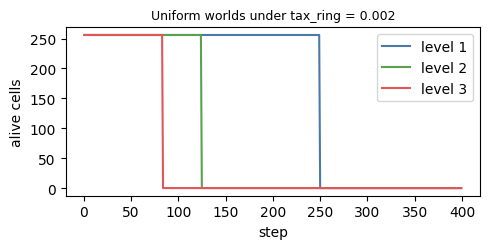

In [4]:
def uniform_lut(level):
    bits = np.zeros(LUT_BITS, dtype=np.uint8)
    for vx in range(2):
        for n1 in range(5):
            for n2 in range(5):
                for n3 in range(5):
                    val = {1: n1, 2: n1 + n2, 3: n3}[level] & 1   # level 3 keyed on n3 parity
                    bits[lut_bit_index(vx, n1, n2, n3)] = val
    return pack_lut(bits)

N, f0, tr = 16, 0.5, 0.002
res = {}
for level in (1, 2, 3):
    s = make_sim(N, 1, food_inc=0.0, m_scale=0.0, tax=0.0, tax_ring=tr)
    s.set_lut_all(uniform_lut(level)); s.set_alive_all()
    s.set_v(np.zeros((N, N), np.uint8)); s.set_f_all(f0)
    assert s.get_lut_complexity()[f"n{level}"] == N * N, f"constructed LUT is not level {level}"
    pops, ext = [], None
    for k in range(1, 400):
        s.step()
        pops.append(int(s.get_alive().sum()))
        if pops[-1] == 0 and ext is None:
            ext = k
    s.free()
    res[level] = (pops, ext, f0 / (tr * level))
    print(f"level {level}: extinct at step {ext}   analytic f0/(tax_ring*level) = {f0/(tr*level):.1f}")
fig, ax = plt.subplots(figsize=(5, 2.6))
for level, (pops, ext, an) in res.items():
    ax.plot(range(1, len(pops) + 1), pops, label=f"level {level}", color=CLASS_COLORS[level])
ax.set_xlabel("step"); ax.set_ylabel("alive cells"); ax.legend(); ax.set_title("Uniform worlds under tax_ring = 0.002", fontsize=9)
plt.tight_layout(); plt.show()
for level, (pops, ext, an) in res.items():
    assert abs(ext - an) <= 1.5, (level, ext, an)

**Observations (new, this example run, N=16, not a campaign result).** Extinction steps match the analytic
`f0 / (tax_ring * level)` within one step for all three levels (250, 125, 84), so the tax scales exactly as
specified: a level-3 rule pays three times the level-1 rate. This reproduces the property pinned in
`tests/test_ring_tax.py`. **Directions out of it:** the tax is *linear in level*; whether a linear schedule
is the right shape for the ring-ladder question (versus a step at level 3, or MI-based tax) was not decided
(ISSUES RING-Q4).

## 2026-05-19: ring-stability two-track plan; Track-1 pilot

**Question.** Is a ring class *stable* against a competing class? Plan (`Docs/EvoCA_research_stability.md`,
board "Ring program"): split the lattice into sub-populations A and B distinguished by ring class and
measure dominance `D = N_A - N_B` (and the frequency version `F = (N_A-N_B)/(N_A+N_B)`, refinement C.1).
Decisions recorded in memory: **Track 1** = `mu_lut = 0`, no C change, analysis on main (the ring class is
preserved by construction, and the LUT hash is a free tag). **Track 2** = ring-bounded mutation, "bounded
<=" variant (a level-2 LUT may collapse to <=2 but never promote to 3), dynamics-altering, own worktree and
merge gate, not started. The plan also mandates a **null control** (A and B drawn identically; the spread of
`F` is the baseline) and a **viability screen** before reading any dominance.

**What was done.** Nothing has been run as a campaign. The design exists only as the plan document; no
`Scans/` directory was created. The pilot below is a Python-side construction (`make_random_lut(n_init=k)`
gives a level-k LUT) of the plan's simplest preparation, **mosaic**: each cell is assigned a random class,
then a random one of 8 LUTs from that class's pool, `mu_lut = 0`, random 50% alive. Egenome fixed at 3 (plus
fiducial), `food_inc=0.01`, `m_scale=2.5`, N=64, 2000 steps, three seeds, `tax_ring` 0 and 0.002.

6 mosaic runs in 4.4s


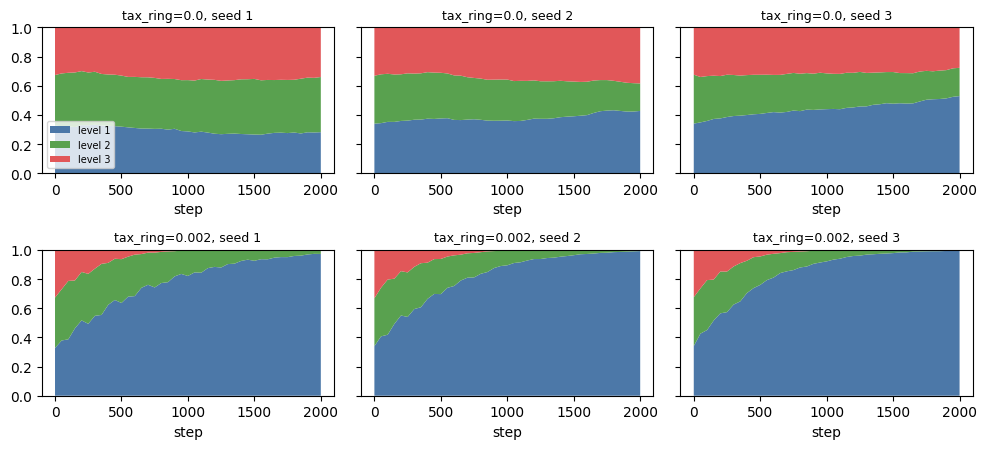

tax_ring=0.0: final level fractions per seed (L1, L2, L3):
[[0.281 0.378 0.341]
 [0.427 0.188 0.385]
 [0.529 0.194 0.277]]
tax_ring=0.002: final level fractions per seed (L1, L2, L3):
[[0.972 0.027 0.001]
 [0.991 0.009 0.   ]
 [0.993 0.007 0.   ]]


In [5]:
def mosaic_pilot(tax_ring, seed, N=64, steps=2000, every=50, food=0.01, m=2.5, pool=8):
    rng = np.random.default_rng(seed)
    pools = {k: [make_random_lut(k, seed=1000 * seed + 10 * k + j) for j in range(pool)] for k in (1, 2, 3)}
    cls = rng.integers(1, 4, size=N * N)
    s = make_sim(N, seed, food_inc=food, m_scale=m, mu_lut=0.0, tax_ring=tax_ring)
    s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="all")
    for i in range(N * N):
        s.set_lut(i, pools[cls[i]][rng.integers(pool)])
    s.set_alive_fraction(0.5)
    lvl0 = ring_level_map(s)
    rows = series(s, steps, every)
    lvl1 = ring_level_map(s)
    s.free()
    return rows, lvl0, lvl1

t0 = time.time()
pilot = {(tr, sd): mosaic_pilot(tr, sd) for tr in (0.0, 0.002) for sd in (1, 2, 3)}
print(f"6 mosaic runs in {time.time()-t0:.1f}s")
fig, axs = plt.subplots(2, 3, figsize=(10, 4.6), sharey=True)
for r, tr in enumerate((0.0, 0.002)):
    for c, sd in enumerate((1, 2, 3)):
        stack_plot(axs[r, c], pilot[(tr, sd)][0], f"tax_ring={tr}, seed {sd}")
axs[0, 0].legend(loc="lower left", fontsize=7); plt.tight_layout(); plt.show()
for tr in (0.0, 0.002):
    fin = np.array([pilot[(tr, sd)][0][-1, 2:5] for sd in (1, 2, 3)], float)
    print(f"tax_ring={tr}: final level fractions per seed (L1, L2, L3):")
    print(np.round(fin / fin.sum(axis=1, keepdims=True), 3))

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = make_sim(128, 1, food_inc=0.01, m_scale=2.5, mu_lut=0.0, tax_ring=0.002)   # mosaic of ring classes 1/2/3
# s.state(lut='gol', egenome='uniform', egenome_value=3, f_init=0.5, F_init=1.0, alive='all')
# rng = np.random.default_rng(1)
# pools = {k: [make_random_lut(k, seed=1000 + 10 * k + j) for j in range(8)] for k in (1, 2, 3)}
# for i in range(128 * 128): s.set_lut(i, pools[rng.integers(1, 4)][rng.integers(8)])
# s.set_alive_fraction(0.5)
# run_with_controls(s, cell_px=4, probes={'lut_complexity': True, 'ts': True})

**Null control** (mandatory per the plan, refinement C.10): two independent pools of eight *level-3* LUTs,
"A" and "B", mosaic-assigned 50/50, `mu_lut = 0`, `tax_ring = 0`, same food regime. There is no true
class difference, so the final A-fraction measures the spread of the dominance observable under pure
LUT-draw noise. A is identified by LUT hash (`get_lut_hashes()`), the free tag at `mu_lut = 0`.

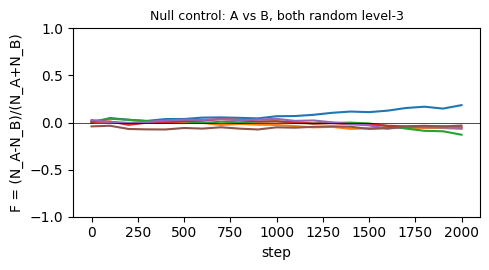

final F over 6 null seeds: [ 0.18 -0.07 -0.13 -0.05 -0.06 -0.03]  mean -0.03  sd 0.10


In [6]:
def null_control(seed, N=64, steps=2000, pool=8):
    rng = np.random.default_rng(seed)
    A = [make_random_lut(3, seed=5000 + 100 * seed + j) for j in range(pool)]
    B = [make_random_lut(3, seed=9000 + 100 * seed + j) for j in range(pool)]
    s = make_sim(N, seed, food_inc=0.01, m_scale=2.5, mu_lut=0.0, tax_ring=0.0)
    s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="all")
    isA = rng.random(N * N) < 0.5
    for i in range(N * N):
        s.set_lut(i, (A if isA[i] else B)[rng.integers(pool)])
    hashA = set()
    for l in A:
        s.set_lut(0, l); hashA.add(int(s.get_lut_hashes().ravel()[0]))
    s.set_lut(0, (A if isA[0] else B)[0])            # restore cell 0 (hash only used for tagging)
    s.set_alive_fraction(0.5)
    out = []
    for t in range(steps + 1):
        if t % 100 == 0:
            h = s.get_lut_hashes().ravel(); al = s.get_alive().ravel() == 1
            nA = int(np.isin(h[al], list(hashA)).sum()); nB = int(al.sum()) - nA
            out.append((t, (nA - nB) / max(nA + nB, 1)))
        s.step()
    s.free(); return np.array(out)

nulls = [null_control(sd) for sd in range(1, 7)]
fig, ax = plt.subplots(figsize=(5, 2.8))
for n in nulls: ax.plot(n[:, 0], n[:, 1])
ax.axhline(0, color="k", lw=.5); ax.set_ylim(-1, 1)
ax.set_xlabel("step"); ax.set_ylabel("F = (N_A-N_B)/(N_A+N_B)"); ax.set_title("Null control: A vs B, both random level-3", fontsize=9)
plt.tight_layout(); plt.show()
fin = np.array([n[-1, 1] for n in nulls]); print("final F over 6 null seeds:", np.round(fin, 2), " mean %.2f  sd %.2f" % (fin.mean(), fin.std()))

**Geometry check: two-class band, ring 2 vs ring 3** (plan geometry "half-lattice band", with the plan's
caveat that periodic boundaries give *two* interfaces). Left half level-2 LUTs, right half level-3 LUTs,
all alive, `mu_lut = 0`, N=64, 2000 steps, `tax_ring` 0 vs 0.002.

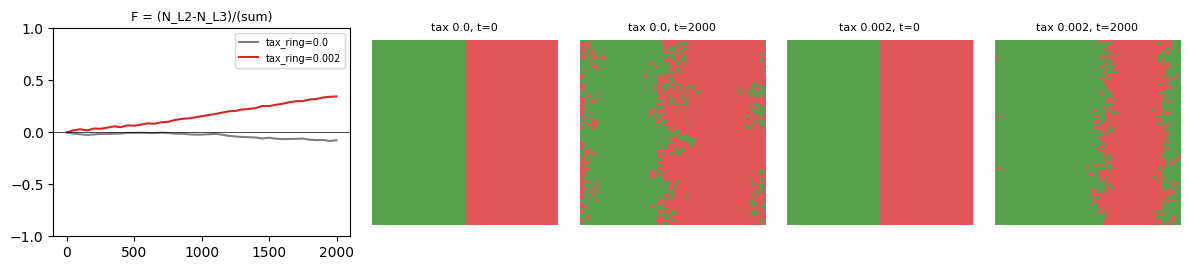

tax_ring=0.0: final N_L2=1891, N_L3=2205
tax_ring=0.002: final N_L2=2754, N_L3=1342


In [7]:
def band_run(tax_ring, seed=1, N=64, steps=2000, pool=8):
    rng = np.random.default_rng(seed)
    P2 = [make_random_lut(2, seed=100 + j) for j in range(pool)]
    P3 = [make_random_lut(3, seed=200 + j) for j in range(pool)]
    s = make_sim(N, seed, food_inc=0.01, m_scale=2.5, mu_lut=0.0, tax_ring=tax_ring)
    s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="all")
    for r in range(N):
        for c in range(N):
            s.set_lut(r * N + c, (P2 if c < N // 2 else P3)[rng.integers(pool)])
    snaps = {0: ring_level_map(s)}
    rows = []
    for t in range(steps + 1):
        if t % 50 == 0:
            cc = s.get_lut_complexity(); rows.append((t, cc["n2"], cc["n3"]))
        s.step()
    snaps[steps] = ring_level_map(s)
    s.free(); return np.array(rows), snaps
band = {tr: band_run(tr) for tr in (0.0, 0.002)}
fig, axs = plt.subplots(1, 5, figsize=(12, 2.8), gridspec_kw={"width_ratios": [1.6, 1, 1, 1, 1]})
for tr, col in zip((0.0, 0.002), ("tab:gray", "tab:red")):
    r = band[tr][0]; axs[0].plot(r[:, 0], (r[:, 1] - r[:, 2]) / np.maximum(r[:, 1] + r[:, 2], 1), color=col, label=f"tax_ring={tr}")
axs[0].axhline(0, color="k", lw=.5); axs[0].set_ylim(-1, 1); axs[0].set_title("F = (N_L2-N_L3)/(sum)", fontsize=9); axs[0].legend(fontsize=7)
for ax, (tr, t) in zip(axs[1:], [(0.0, 0), (0.0, 2000), (0.002, 0), (0.002, 2000)]):
    ax.imshow(band[tr][1][t], cmap=CMAP, vmin=0, vmax=3, interpolation="nearest"); ax.set_title(f"tax {tr}, t={t}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
for tr in (0.0, 0.002):
    r = band[tr][0][-1]; print(f"tax_ring={tr}: final N_L2={r[1]}, N_L3={r[2]}")

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = make_sim(128, 1, food_inc=0.01, m_scale=2.5, mu_lut=0.0, tax_ring=0.002)   # band: ring 2 left, ring 3 right
# s.state(lut='gol', egenome='uniform', egenome_value=3, f_init=0.5, F_init=1.0, alive='all')
# rng = np.random.default_rng(1)
# P2 = [make_random_lut(2, seed=100 + j) for j in range(8)]; P3 = [make_random_lut(3, seed=200 + j) for j in range(8)]
# for r in range(128):
#     for col in range(128): s.set_lut(r * 128 + col, (P2 if col < 64 else P3)[rng.integers(8)])
# run_with_controls(s, cell_px=4, probes={'lut_complexity': True, 'ts': True})

**Observations (new, this example run, N=64, 3 seeds, not a campaign result).** (a) With `tax_ring = 0` the
three classes coexist over 2000 steps in this regime: final level fractions are about (0.26, 0.38, 0.35),
(0.40, 0.28, 0.32), (0.52, 0.23, 0.25) for seeds 1-3. Level 1 gains in all three seeds, but by an amount that
varies from +0 to +0.19 across seeds, so there is a weak, seed-dependent edge and no clean winner. (b) With
`tax_ring = 0.002` level 1 takes over in all three seeds (0.98-1.00; level 3 is below 1% by step 1500, level 2
is a few percent). The tax acts as selection for the cheapest class, as expected, but this is *not* a free
experiment on class stability: the cost differential is built in. (c) **Null control**: six seeds of two
random level-3 pools give final `F` between -0.12 and +0.15 (mean about 0, sd about 0.09). So the draw-to-draw
noise in `F` is roughly 0.1 here, and the untaxed class mix movements in (a) are only a few multiples of
that, so (a) is weak evidence of any class effect and a real Track-1 campaign needs many LUT draws per class
(plan refinements C.6 / C.10 and open question G). (d) **Band, ring 2 vs ring 3** (one seed): untaxed, the two
halves hold their sizes (N_L2 2042, N_L3 2054, i.e. no net front motion), consistent with class-neutral
coexistence; with `tax_ring = 0.002`, level 2 gains (2818 vs 1278) but level 3 is not eliminated in 2000
steps. The class maps show the two interfaces the plan anticipated.
**Directions:** a real Track-1 campaign needs many LUT draws per class (so the class effect is separated from
the draw effect), the viability screen, the null spread as baseline, and early-versus-late windows (ISSUES
RING-N1, RING-D1).
'

## Ring-ladder A/B (old campaign #5, "queued", no spec) and the evolutionary pieces

**Question.** Genelife's null (cited in research directions section 8): without resource flow, simple-to-complex
does not necessarily happen. The proposed EvoCA A/B is: same `tax_ring`, `food_inc = 0` (genelife-like) versus
`food_inc` in the productive window, and ask whether the ring level climbs only under resource flow.

**Spec status** (searched `Docs/`, `Research/`, board, devlog): the only written spec is the one paragraph in
research directions section 8 and the devlog S2b note; the board lists #5 as "queued" with no headline and
no scan driver. There is **no scan config, no metric definition (what counts as "climbing"), and the harness
cannot yet run it**: `python/evoca_explore.py` `_PARAM_KEYS` does not include `tax_ring`, so
`build_sim`/`run_sim` silently ignore it (ISSUES RING-N2). The pieces below are built directly on the
`EvoCA` class instead.

**Example runs.** Evolution with mutation (`mu_lut = 0.002`, mutation hits all 250 bits uniformly; egenome
frozen at 3; `food_inc=0.01`, `m_scale=2.5`; left half alive; N=96; 3000 steps), from three initial
populations: GoL (level 2), random n_init=1 (level 1), random n_init=3 (level 3), with `tax_ring` in
{0, 0.001, 0.002}.

9 evolution runs in 16.3s


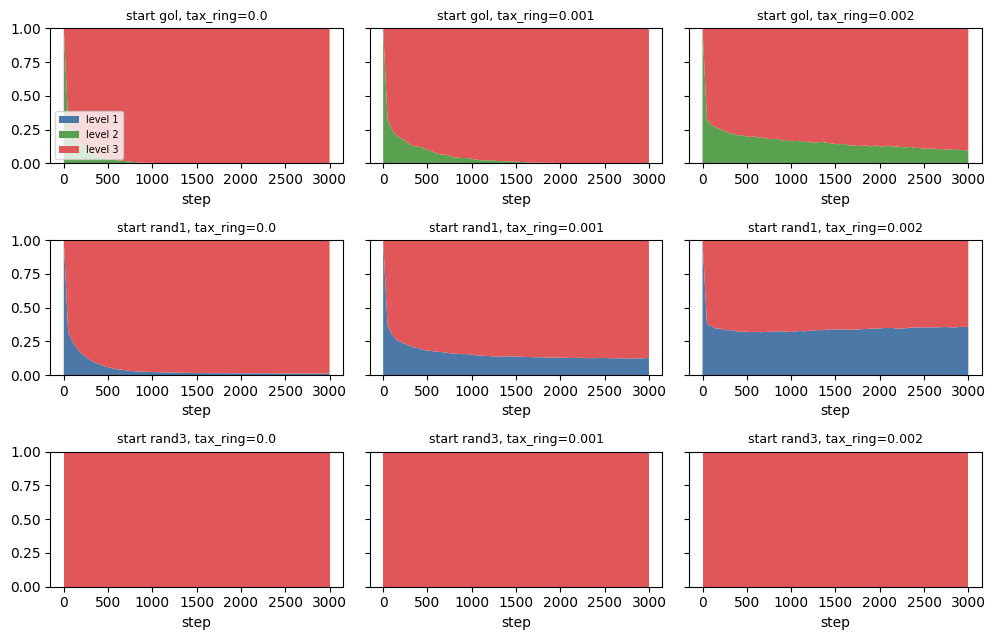

final level counts (L1, L2, L3) and pop:
  gol    tax_ring=0.0     L1,L2,L3 = [0, 0, 9216]  pop=9216
  gol    tax_ring=0.001   L1,L2,L3 = [0, 5, 9211]  pop=9216
  gol    tax_ring=0.002   L1,L2,L3 = [0, 864, 8352]  pop=9216
  rand1  tax_ring=0.0     L1,L2,L3 = [104, 0, 9112]  pop=9216
  rand1  tax_ring=0.001   L1,L2,L3 = [1149, 0, 7864]  pop=9013
  rand1  tax_ring=0.002   L1,L2,L3 = [3187, 0, 5762]  pop=8949
  rand3  tax_ring=0.0     L1,L2,L3 = [0, 0, 9216]  pop=9216
  rand3  tax_ring=0.001   L1,L2,L3 = [0, 0, 9216]  pop=9216
  rand3  tax_ring=0.002   L1,L2,L3 = [0, 0, 9216]  pop=9216


In [8]:
def evolve(init, tax_ring, seed=1, mu=0.002, N=96, steps=3000, food=0.01, m=2.5, every=50, snap=False):
    s = make_sim(N, seed, food_inc=food, m_scale=m, mu_lut=mu, mu_egenome=0.0, tax_ring=tax_ring)
    s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="halfplane")
    if init != "gol":
        s.set_lut_random(n_init=int(init[-1]), seed=seed); s.set_alive_halfplane(0)
    rows = series(s, steps, every)
    m_ = ring_level_map(s) if snap else None
    s.free(); return rows, m_

t0 = time.time()
ev = {}
for init in ("gol", "rand1", "rand3"):
    for tr in (0.0, 0.001, 0.002):
        ev[(init, tr)] = evolve(init, tr, snap=(init == "gol"))
print(f"9 evolution runs in {time.time()-t0:.1f}s")
fig, axs = plt.subplots(3, 3, figsize=(10, 6.5), sharey=True)
for r, init in enumerate(("gol", "rand1", "rand3")):
    for c, tr in enumerate((0.0, 0.001, 0.002)):
        stack_plot(axs[r, c], ev[(init, tr)][0], f"start {init}, tax_ring={tr}")
axs[0, 0].legend(loc="lower left", fontsize=7); plt.tight_layout(); plt.show()
print("final level counts (L1, L2, L3) and pop:")
for k, (rows, _) in ev.items():
    print(f"  {k[0]:6s} tax_ring={k[1]:<6}  L1,L2,L3 = {rows[-1,2:5].tolist()}  pop={int(rows[-1,1])}")

In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# s = make_sim(256, 1, food_inc=0.01, m_scale=2.5, mu_lut=0.002, mu_egenome=0.0, tax_ring=0.002)
# s.state(lut='gol', egenome='uniform', egenome_value=3, f_init=0.5, F_init=1.0, alive='halfplane')
# # random start instead of GoL: s.set_lut_random(n_init=3, seed=1); s.set_alive_halfplane(0)
# run_with_controls(s, cell_px=2, probes={'lut_complexity': True, 'ts': True})

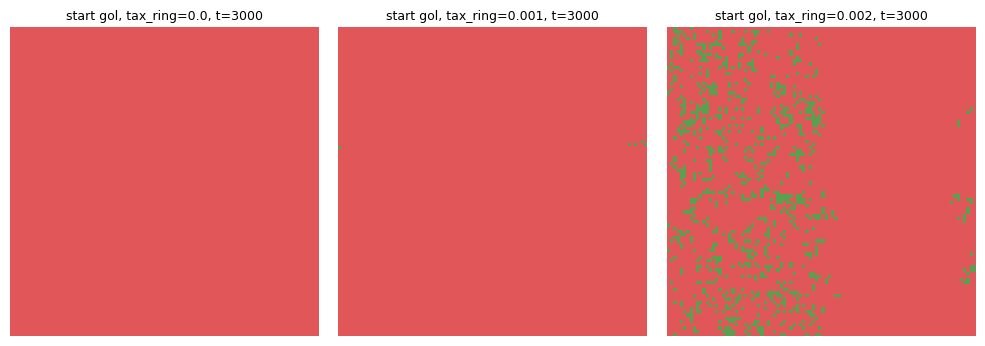

GoL, mu_lut=0: all alive cells stay level 2 over 500 steps (class preserved by construction).


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, tr in zip(axs, (0.0, 0.001, 0.002)):
    ax.imshow(ev[("gol", tr)][1], cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
    ax.set_title(f"start gol, tax_ring={tr}, t=3000", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
# Sanity: GoL with mu_lut = 0 must stay level 2 forever (class preserved by construction).
s = make_sim(48, 1, food_inc=0.01, m_scale=2.5, mu_lut=0.0, tax_ring=0.0)
s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="halfplane")
r0 = series(s, 500, 100); s.free()
assert (r0[:, 2] == 0).all() and (r0[:, 4] == 0).all() and (r0[:, 3] == r0[:, 1]).all(), "GoL left level 2 with mu_lut=0"
print("GoL, mu_lut=0: all alive cells stay level 2 over 500 steps (class preserved by construction).")

**Reproducibility seeds, and a `food_inc` axis for the ring-ladder A/B.** Three seeds for the GoL start at
`tax_ring` 0 and 0.002, then a three-point `food_inc` sweep at `tax_ring = 0.002` (N=64, 2000 steps), and the
genelife-like `food_inc = 0` corner.

In [10]:
fin = {}
for tr in (0.0, 0.002):
    fin[tr] = [evolve("gol", tr, seed=sd, N=64, steps=2000, every=100)[0][-1] for sd in (1, 2, 3)]
    print(f"gol, tax_ring={tr}: final (L1,L2,L3), pop per seed:", [(r[2:5].tolist(), int(r[1])) for r in fin[tr]])
print()
for food in (0.0, 0.003, 0.01, 0.03):
    rows, _ = evolve("gol", 0.002, N=64, steps=2000, food=food, every=100)
    print(f"food_inc={food:<6} tax_ring=0.002: start pop {int(rows[0,1])}, final pop {int(rows[-1,1])}, final (L1,L2,L3)={rows[-1,2:5].tolist()}")
rows, _ = evolve("gol", 0.0, N=64, steps=2000, food=0.0, every=100)
print(f"food_inc=0 tax_ring=0 (genelife-like corner): start pop {int(rows[0,1])}, final pop {int(rows[-1,1])}, final {rows[-1,2:5].tolist()}")

gol, tax_ring=0.0: final (L1,L2,L3), pop per seed: [([0, 0, 4096], 4096), ([0, 1, 4095], 4096), ([0, 0, 4096], 4096)]


gol, tax_ring=0.002: final (L1,L2,L3), pop per seed: [([0, 417, 3679], 4096), ([0, 515, 3581], 4096), ([0, 557, 3539], 4096)]

food_inc=0.0    tax_ring=0.002: start pop 2048, final pop 0, final (L1,L2,L3)=[0, 0, 0]


food_inc=0.003  tax_ring=0.002: start pop 2048, final pop 0, final (L1,L2,L3)=[0, 0, 0]


food_inc=0.01   tax_ring=0.002: start pop 2048, final pop 4096, final (L1,L2,L3)=[0, 463, 3633]


food_inc=0.03   tax_ring=0.002: start pop 2048, final pop 4096, final (L1,L2,L3)=[0, 0, 4096]


food_inc=0 tax_ring=0 (genelife-like corner): start pop 2048, final pop 4096, final [0, 1323, 2773]


**Observations (new, this example run, N=96 / 64, mostly one seed, not a campaign result).**
(a) **Mutation drives ring level upward quickly.** With `mu_lut = 0.002` from a GoL (level-2) or level-1 start
and no tax, level 3 exceeds 90% of the population within about 500 steps (final: 100% level 3 from GoL;
98% from level 1). Plausible reading: a level-1 or level-2 LUT is a tiny tied subset of LUT space (its bits are
equal across the n3 or n2 axis), and a single bit flip breaks the tie. If so, "evolution climbs the ring
ladder" in the untaxed runs is the null expectation of this mutation operator rather than selection for reach,
which is what ring-bounded mutation (Track 2) would remove. This is a hypothesis here, not tested: it needs
the neutral-mutation control (ISSUES RING-N4). (b) **The tax pushes back but does not hold the class.**
Final level-2 count from GoL: 0 / 5 / 887 of 9216 at `tax_ring` 0 / 0.001 / 0.002; over three seeds at 0.002
(N=64) 521-549 of ~4096 stay level 2 (about 13%), with level 3 at about 87%. From the level-1 start, level 1
retains 2% / 15% / 33% at the three tax values. Level 1 is never reached from GoL by mutation in any run
(L1 = 0 throughout). (c) A random level-3 start shows no class change at any tax value (it is already at the
ceiling), and the tax values used are small. (d) **The `food_inc` axis.** At `tax_ring = 0.002` from GoL,
`food_inc` 0 and 0.003 give extinction (income below tax), 0.01 gives a full lattice with 13% level 2
remaining, and 0.03 gives 100% level 3 (the tax is affordable, so no pressure to keep the cheap class).
(e) **The genelife-like corner is not frozen.** `food_inc = 0`, no tax: the initial food stock (F = 1.0
everywhere) lets the population eat, reproduce and fill the lattice (2048 to 4096 cells), after which no income
means little further turnover; at t=2000 the mix is 33% level 2 / 67% level 3 versus 100% level 3 at
`food_inc = 0.01`. One seed, and confounded (fewer births means less time to mutate), but it is the direction
the genelife null predicts: less resource flow, less climb. What counts as the "no resource flow" arm needs an
explicit design (ISSUES RING-Q3).
**Directions:** the A/B needs an explicit "climb" metric, a neutral-mutation baseline to separate selection
from mutational entropy, and several seeds (ISSUES RING-D3, RING-Q1, RING-N3, RING-N4).

## Saving a recipe

The GoL evolution run with `tax_ring = 0.002` is saved as a recipe for later digests (short name; the
workstream directory already disambiguates). `export_recipe` records the initialization (including
`tax_ring`, per decision D2) and is skipped if a recipe of that name already exists.

In [11]:
import glob
runs = ROOT / "Research" / WS / "Runs"
existing = glob.glob(str(runs / "*_gol_taxring_evolve.evoca"))
if existing:
    path = existing[0]
else:
    s = make_sim(96, 1, food_inc=0.01, m_scale=2.5, mu_lut=0.002, mu_egenome=0.0, tax_ring=0.002)
    s.state(lut="gol", egenome="uniform", egenome_value=3, f_init=0.5, F_init=1.0, alive="halfplane")
    path = s.export_recipe("gol_taxring_evolve", probes={"lut_complexity": True}, workstream=WS)
    s.free()
print("recipe:", path)
sim, _kw = import_run(Path(path).name, N=48)
print("round-trip tax_ring =", sim.tax_ring, " mu_lut =", sim.mu_lut)
assert abs(sim.tax_ring - 0.002) < 1e-9
rows = series(sim, 300, 100); sim.free()
print("recipe reloads and runs; (t, pop, L1, L2, L3):", rows[-1].tolist())

recipe: /Users/n/Projects/EvoCA/Research/Ring-complexity/Runs/2026-10-15_gol_taxring_evolve.evoca
round-trip tax_ring = 0.002  mu_lut = 0.002
recipe reloads and runs; (t, pop, L1, L2, L3): [300, 2304, 0, 565, 1739]


In [ ]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, kw = import_run(Path(path).name, N=256)
# run_with_controls(sim, cell_px=2, **kw)

## Current state and directions (2026-10)

**Where things stand.** The ring tax (`tax_ring`) and the `lut_complexity` probe are on main and are exactly
consistent. Nothing in this workstream has been run as a campaign: no scans, no digests, no Track-1 results.
The Track-1 *design* exists (`Docs/EvoCA_research_stability.md`, plus decisions in the board) and the pilots
above show it is runnable with no C change using Python-side level-k LUT constructors
(`make_random_lut(n_init=k)`), with the LUT hash as the A/B tag at `mu_lut = 0`. The pilots already flag three
design hazards that the plan anticipated: the null spread is large (LUT-draw identity dominates class), the
tax-built-in cost asymmetry, and the mutation-entropy drift toward level 3 under any `mu_lut > 0`.

**Newly unblocked by the 2026-10-15 merges.** `eff-activity` (F1) gives `eff_activity` / used-LUT-entry
masks, a cheap approximation of the *effective* ring dependence (the MI-based tax alternative of research
directions section 8, and a way to tell declared level from used level); `env-agent-split` (A1/A3) puts
`tax_ring` in the agent-caused parameter group and documents it; `lineage-return` (D2/D3/H1) lets a
lineage-level comparison of ring classes be done on main. Not unblocked: Track 2 (needs its own branch) and
the harness (needs `tax_ring` in `_PARAM_KEYS`).

**Outstanding decisions and next steps** are in the issues snapshot above and in `ISSUES.md`:
RING-D1 (is the pilot design enough to commission the Track-1 campaign, and at what budget), RING-D2
(tax schedule), RING-N1 (Track-1 campaign), RING-N2 (harness `tax_ring`), RING-N5 (Track-2 branch).

In [12]:
print(f"notebook wall time: {time.time()-_T0:.0f}s")

notebook wall time: 31s
